# Feature Engineering: Student Pass/Fail Clustering

**Rules**
1. Remove `actual` before starting; use it only at the end to check accuracy.
2. Never build a feature from `actual`.

In [33]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    silhouette_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
)

## Step 0: Load data and set `actual` aside

In [34]:
df = pd.read_csv("students_dataset.csv")
print("Shape:", df.shape)

# Remove 'actual' BEFORE cleaning or feature engineering
actual = df.pop("actual")
if actual.isna().any() or not actual.isin(["Pass", "Fail"]).all():
    raise ValueError("actual must contain only non-missing Pass/Fail labels")
y = (actual == "Pass").astype(int)   # Pass = 1, Fail = 0
print(y.value_counts())
df.head()

Shape: (600, 7)
actual
1    390
0    210
Name: count, dtype: int64


,study_hours_per_week,attendance_pct,previous_grade,assignments_done_pct,sleep_hours,absences
0,10.765100,73.179949,68.338955,74.195911,8.370910,8
1,2.107447,68.276768,56.059828,72.322099,7.271699,16
2,14.825146,88.945197,71.570000,86.817146,9.266308,0
3,9.879496,86.807741,73.009585,79.311205,5.828393,8
4,0.000000,59.837773,42.326410,42.928179,5.954226,12


## Step 1: Clean
Remove duplicate rows and fill empty cells with the column median.

In [35]:
source_rows = df.assign(actual=y)
print("Duplicates before:", source_rows.duplicated().sum())
print("Empty feature cells before:\n", df.isna().sum())

# Remove exact duplicate observations and keep y aligned
keep = ~source_rows.duplicated()
df, y = df.loc[keep].reset_index(drop=True), y.loc[keep].reset_index(drop=True)

# Fill empty feature cells with column median
df = df.fillna(df.median())

print("\nDuplicates after:", df.assign(actual=y).duplicated().sum())
print("Empty feature cells after:\n", df.isna().sum())

Duplicates before: 0
Empty feature cells before:
 study_hours_per_week    0
attendance_pct          0
previous_grade          0
assignments_done_pct    0
sleep_hours             0
absences                0
dtype: int64

Duplicates after: 0
Empty feature cells after:
 study_hours_per_week    0
attendance_pct          0
previous_grade          0
assignments_done_pct    0
sleep_hours             0
absences                0
dtype: int64


## Step 2: Fix wrong values
Make sure percentages are between 0 and 100 and hours are not negative.

In [36]:
pct_cols  = ["attendance_pct", "assignments_done_pct", "previous_grade"]
hour_cols = ["study_hours_per_week", "sleep_hours"]

print("Out-of-range percentages/grades:", ((df[pct_cols] < 0) | (df[pct_cols] > 100)).sum().sum())
print("Negative hours:", (df[hour_cols] < 0).sum().sum())
print("Negative absences:", (df["absences"] < 0).sum())

# Clip to valid range (does nothing if all values are valid)
df[pct_cols]  = df[pct_cols].clip(0, 100)
df[hour_cols] = df[hour_cols].clip(lower=0)
df["absences"] = df["absences"].clip(lower=0)
df.describe().round(2)

Out-of-range percentages/grades: 0
Negative hours: 0
Negative absences: 0


,study_hours_per_week,attendance_pct,previous_grade,assignments_done_pct,sleep_hours,absences
count,600.00,600.00,600.00,600.00,600.00,600.00
mean,7.95,79.14,64.30,74.63,7.02,6.13
std,4.47,10.49,13.88,14.81,1.02,3.96
min,0.00,51.70,24.31,35.34,4.04,0.00
25%,4.48,71.36,55.53,64.21,6.30,3.00
50%,7.94,79.43,64.85,74.81,7.03,6.00
75%,11.09,86.80,73.67,85.09,7.70,9.00
max,23.64,100.00,100.00,100.00,10.00,19.00


## Baseline (Before Feature Engineering)
Snapshot of the original 6 cleaned features.

In [37]:
X_before = df.copy()

## Step 3: Add 2 new features

| Feature | Reason (one sentence) |
|---|---|
| `sleep_deviation` | Too little or too much sleep can hurt results. |
| `risk_count` | More warning signs means higher risk of failing. |

Both use only feature columns, never `actual`.

In [38]:
df["sleep_deviation"] = (df["sleep_hours"] - 8).abs()

df["risk_count"] = (
      (df["study_hours_per_week"] < 2).astype(int)
    + (df["attendance_pct"] < 70).astype(int)
    + (df["previous_grade"] < 50).astype(int)
    + (df["absences"] >= 10).astype(int)
)
df[["sleep_hours", "sleep_deviation", "risk_count"]].head()

,sleep_hours,sleep_deviation,risk_count
0,8.370910,0.370910,0
1,7.271699,0.728301,2
2,9.266308,1.266308,0
3,5.828393,2.171607,0
4,5.954226,2.045774,4


## Step 4: Remove repeated features
If two features have correlation above 0.85, keep only one.

In [39]:
corr = df.corr()
print(corr.round(3))

# Find and remove any repeated features with correlation above 0.85
cols = corr.columns
pairs = [(a, b, round(corr.loc[a, b], 3))
         for i, a in enumerate(cols) for b in cols[i+1:]
         if abs(corr.loc[a, b]) > 0.85]
print("\nPairs above 0.85:", pairs if pairs else "None")

to_drop = {b for _, b, _ in pairs}
if to_drop:
    df = df.drop(columns=list(to_drop))

                      study_hours_per_week  attendance_pct  previous_grade  \
study_hours_per_week                 1.000           0.567           0.627   
attendance_pct                       0.567           1.000           0.583   
previous_grade                       0.627           0.583           1.000   
assignments_done_pct                 0.607           0.539           0.598   
sleep_hours                          0.255           0.241           0.283   
absences                            -0.528          -0.495          -0.556   
sleep_deviation                     -0.216          -0.173          -0.238   
risk_count                          -0.595          -0.675          -0.662   

                      assignments_done_pct  sleep_hours  absences  \
study_hours_per_week                 0.607        0.255    -0.528   
attendance_pct                       0.539        0.241    -0.495   
previous_grade                       0.598        0.283    -0.556   
assignments_done_pct 

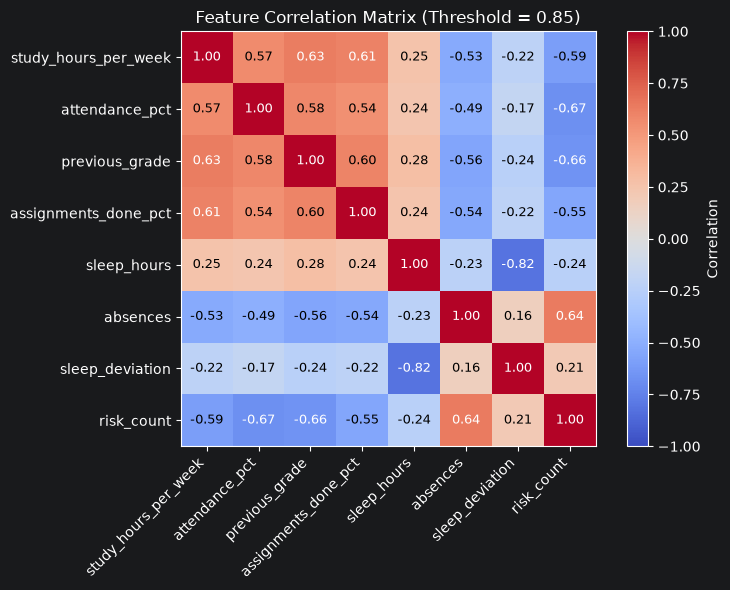

In [40]:
# Graph 1: Feature Correlation Heatmap
fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(im, ax=ax, label="Correlation")

ax.set_xticks(range(len(corr.columns)))
ax.set_yticks(range(len(corr.columns)))
ax.set_xticklabels(corr.columns, rotation=45, ha="right")
ax.set_yticklabels(corr.columns)

for i in range(len(corr.columns)):
    for j in range(len(corr.columns)):
        val = corr.iloc[i, j]
        color = "white" if abs(val) > 0.6 else "black"
        ax.text(j, i, f"{val:.2f}", ha="center", va="center", color=color, fontsize=9)

ax.set_title("Feature Correlation Matrix (Threshold = 0.85)")
plt.tight_layout()
plt.show()

Optional check: `engagement_score = (attendance_pct + assignments_done_pct) / 2` correlates **0.918** with `assignments_done_pct`, so it would be removed as a repeated feature.

In [41]:
eng = (df["attendance_pct"] + df["assignments_done_pct"]) / 2
print("corr(engagement_score, assignments_done_pct) =",
      round(eng.corr(df["assignments_done_pct"]), 3))
print("corr(sleep_deviation, sleep_hours) =",
      round(df["sleep_deviation"].corr(df["sleep_hours"]), 3), "-> below 0.85, keep both")

corr(engagement_score, assignments_done_pct) = 0.918
corr(sleep_deviation, sleep_hours) = -0.815 -> below 0.85, keep both


In [42]:
X_after = df.copy()
print("Final features:", list(X_after.columns))

Final features: ['study_hours_per_week', 'attendance_pct', 'previous_grade', 'assignments_done_pct', 'sleep_hours', 'absences', 'sleep_deviation', 'risk_count']


## Step 5 & 6: Scale and run K-Means

In [43]:
def run_kmeans(X):
    # Scale so all features are on the same scale
    Xs = StandardScaler().fit_transform(X)
    labels = KMeans(n_clusters=2, random_state=42, n_init=10).fit_predict(Xs)
    sil = silhouette_score(Xs, labels)
    # Cluster numbers 0/1 are arbitrary, so use the better mapping
    if accuracy_score(y, labels) < accuracy_score(y, 1 - labels):
        labels = 1 - labels
    metrics = {
        "Accuracy": accuracy_score(y, labels),
        "Precision (Pass)": precision_score(y, labels),
        "Recall (Pass)": recall_score(y, labels),
        "F1-score (Pass)": f1_score(y, labels),
        "Silhouette score": sil,
    }
    return metrics, confusion_matrix(y, labels), labels

metrics_b, cm_b, pred_b = run_kmeans(X_before)
metrics_a, cm_a, pred_a = run_kmeans(X_after)

acc_b, sil_b = metrics_b["Accuracy"], metrics_b["Silhouette score"]
acc_a, sil_a = metrics_a["Accuracy"], metrics_a["Silhouette score"]

## Step 7: Results & Visualizations (use `actual` only now)

In [44]:
results = pd.DataFrame({
    "Before": {k: round(v, 3) for k, v in metrics_b.items()},
    "After": {k: round(v, 3) for k, v in metrics_a.items()},
})
display(results)

print("\n--- Classification Report BEFORE ---")
print(classification_report(y, pred_b, target_names=["Fail", "Pass"], digits=3))

print("--- Classification Report AFTER ---")
print(classification_report(y, pred_a, target_names=["Fail", "Pass"], digits=3))

labels_idx = ["Actually Fail", "Actually Pass"]
labels_col = ["Predicted Fail", "Predicted Pass"]
print("Confusion Matrix BEFORE")
display(pd.DataFrame(cm_b, index=labels_idx, columns=labels_col))
print("Confusion Matrix AFTER")
display(pd.DataFrame(cm_a, index=labels_idx, columns=labels_col))
print(f"Extra students correct: {round((acc_a - acc_b) * len(y))}")

,Before,After
Accuracy,0.822,0.842
Precision (Pass),0.941,0.891
Recall (Pass),0.774,0.862
F1-score (Pass),0.850,0.876
Silhouette score,0.295,0.294



--- Classification Report BEFORE ---
              precision    recall  f1-score   support

        Fail      0.685     0.910     0.781       210
        Pass      0.941     0.774     0.850       390

    accuracy                          0.822       600
   macro avg      0.813     0.842     0.815       600
weighted avg      0.851     0.822     0.826       600

--- Classification Report AFTER ---
              precision    recall  f1-score   support

        Fail      0.758     0.805     0.781       210
        Pass      0.891     0.862     0.876       390

    accuracy                          0.842       600
   macro avg      0.825     0.833     0.828       600
weighted avg      0.845     0.842     0.843       600

Confusion Matrix BEFORE


,Predicted Fail,Predicted Pass
Actually Fail,191,19
Actually Pass,88,302


Confusion Matrix AFTER


,Predicted Fail,Predicted Pass
Actually Fail,169,41
Actually Pass,54,336


Extra students correct: 12


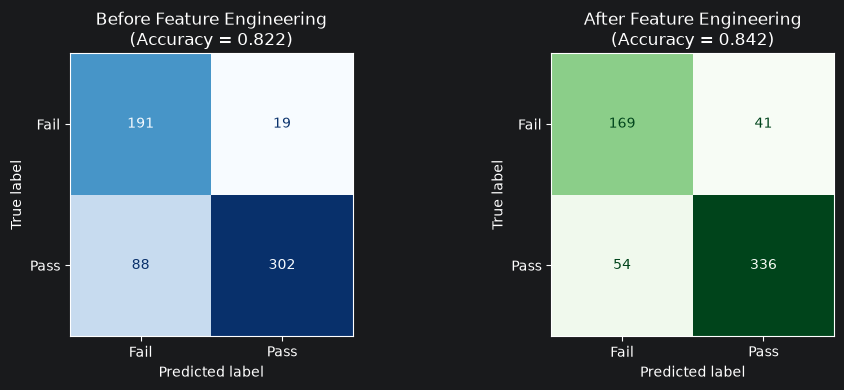

In [45]:
# Graph 2: Side-by-Side Confusion Matrix Heatmaps (Before vs. After)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

ConfusionMatrixDisplay(cm_b, display_labels=["Fail", "Pass"]).plot(
    ax=axes[0], cmap="Blues", colorbar=False
)
axes[0].set_title(f"Before Feature Engineering\n(Accuracy = {acc_b:.3f})")

ConfusionMatrixDisplay(cm_a, display_labels=["Fail", "Pass"]).plot(
    ax=axes[1], cmap="Greens", colorbar=False
)
axes[1].set_title(f"After Feature Engineering\n(Accuracy = {acc_a:.3f})")

plt.tight_layout()
plt.show()

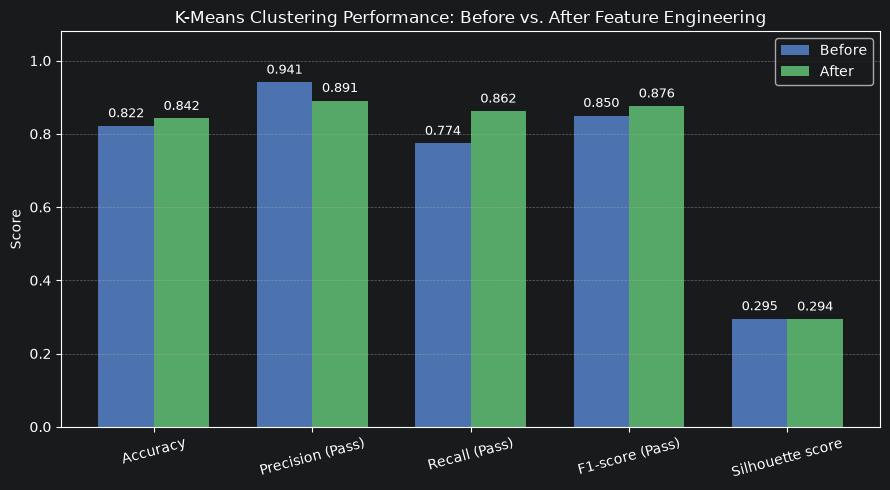

In [46]:
# Graph 3: Before vs. After Evaluation Metrics Comparison
metric_names = list(results.index)
x = np.arange(len(metric_names))
width = 0.35

fig, ax = plt.subplots(figsize=(9, 5))
bars_b = ax.bar(x - width / 2, results["Before"], width, label="Before", color="#4C72B0")
bars_a = ax.bar(x + width / 2, results["After"], width, label="After", color="#55A868")

ax.set_ylabel("Score")
ax.set_title("K-Means Clustering Performance: Before vs. After Feature Engineering")
ax.set_xticks(x)
ax.set_xticklabels(metric_names, rotation=15)
ax.set_ylim(0, 1.08)
ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.5)

for bars in [bars_b, bars_a]:
    for bar in bars:
        h = bar.get_height()
        ax.annotate(
            f"{h:.3f}",
            xy=(bar.get_x() + bar.get_width() / 2, h),
            xytext=(0, 4),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=9,
        )

plt.tight_layout()
plt.show()

## Check: Which new feature helped most? & Bonus (`np.log1p(absences)`)

In [47]:
for name in ["risk_count", "sleep_deviation"]:
    m, _, _ = run_kmeans(X_before.assign(**{name: X_after[name]}))
    print(f"Original + {name:16s}: accuracy={m['Accuracy']:.3f}, silhouette={m['Silhouette score']:.3f}")

# Bonus (optional): apply np.log1p() to skewed 'absences' column and check if it helped
X_bonus = X_after.copy()
X_bonus["absences"] = np.log1p(X_bonus["absences"])
m_bonus, _, _ = run_kmeans(X_bonus)
print(f"Bonus (np.log1p absences)  : accuracy={m_bonus['Accuracy']:.3f}, silhouette={m_bonus['Silhouette score']:.3f}")

Original + risk_count      : accuracy=0.858, silhouette=0.312
Original + sleep_deviation : accuracy=0.818, silhouette=0.275
Bonus (np.log1p absences)  : accuracy=0.825, silhouette=0.274


## Step 8: Explanation

Accuracy improved from 0.822 to 0.842 (12 more students grouped correctly), driven by a strong increase in Pass recall from 0.774 to 0.862 and Pass F1-score from 0.850 to 0.876, while the silhouette score stayed nearly the same (0.295 to 0.294). The `risk_count` feature helped the most because it combines four key warning signs into a single clear indicator (reaching 0.858 accuracy on its own), whereas `sleep_deviation` alone slightly reduced cluster separation (0.818 accuracy). Applying the optional `np.log1p()` transform to `absences` did not improve accuracy further because large raw absence counts help separate failing students.

## Save the new dataset

In [48]:
X_after.to_csv("students_new_features.csv", index=False)
print("Saved: students_new_features.csv", X_after.shape)

Saved: students_new_features.csv (600, 8)
